# Task 1: Use Linear Regression to predict Q

### Subtask 1: Fit Linear Regression model to relevant variables (n , P , Δp , and others) and predict Q (flow)
### Subtask 2: Report test error (MSE)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, train_test_split, KFold, cross_val_score
from sklearn.linear_model import LassoCV, RidgeCV, LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score


In [2]:
# load data for case 1
df_train1 = pd.read_csv('../data/case1/train1.csv')
df_test1 = pd.read_csv('../data/case1/test1.csv')

for df in [df_train1, df_test1]:
    # change to binary 
    mapping = {
        "stable": 0,
        "transient": 1
    }
    df['operating_state'] = df['operating_state'].map(mapping)

    # speed in krpm, n
    df['krpm'] = df['speed_rpm'] / 1000

    # pressure rise across pump
    df['delta_P'] = (
        df['outlet_pressure_bar']
        - df['inlet_pressure_bar']
    )

    # speed terms
    df['n2'] = df['krpm']**2

    # power terms
    df['P2'] = df['power_w']**2

    # delta terms
    df['delta_P2'] = df['delta_P']**2

    # interaction terms
    df['nP'] = df['krpm'] * df['power_w']
    df['n_delta_P'] = df['krpm'] * df['delta_P']
    df['P_delta_P'] = df['power_w'] * df['delta_P']


In [ ]:
# model 1_1 – only original features

X_1 = df_train1[
    [
        'krpm',
        'power_w',
        'delta_P'
    ]
]

# model 1_2 – original + polynomial

X_2 = df_train1[
    [
        'krpm',
        'power_w',
        'delta_P',

        # speed terms
        'n2',
    
        # power terms
        'P2',
    
        # delta terms
        'delta_P2',
    ]
]

# model 1_3 – original + polynomial + interaction features

X_3 = df_train1[
    [
        'krpm',
        'power_w',
        'delta_P',
        
        # speed terms
        'n2',
    
        # power terms
        'P2',
    
        # delta terms
        'delta_P2',

        # interaction terms
        'nP',
        'n_delta_P',
        'P_delta_P'
    ]
]

In [4]:
# compute MSE to choose the best model

train_features = {
    '1_1 original': X_1,
    '1_2 original + poly': X_2,
    '1_3 original + poly + interactions': X_3,
}

y_train = df_train1['flow_m3_h']
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, X_train in train_features.items():
    fold_mse = -cross_val_score(
        LinearRegression(), X_train, y_train, cv=kf,
        scoring='neg_mean_squared_error')
    cv_rows.append({
        'model': name,
        'n_features': X_train.shape[1],
        'CV MSE (mean)': fold_mse.mean(),
        'CV MSE (std)': fold_mse.std(),
        'CV RMSE': np.sqrt(fold_mse.mean()),
    })

cv_results = pd.DataFrame(cv_rows).set_index('model')
print(cv_results.round(4).to_string())

best_name = cv_results['CV MSE (mean)'].idxmin()
print(f"\nSelected by CV: {best_name}")

                                    n_features  CV MSE (mean)  CV MSE (std)  CV RMSE
model                                                                               
1_1 original                                 3        12.1362        1.0845   3.4837
1_2 original + poly                          6         4.0643        0.4413   2.0160
1_3 original + poly + interactions           9         1.5291        0.1628   1.2365

Selected by CV: 1_3 original + poly + interactions


### Best model: model 1_3 – original + polynomial + interaction features

In [5]:
best_model = LinearRegression()

best_model.fit(X_3, y_train)

X_test = df_test1[
    [
        'krpm',
        'power_w',
        'delta_P',
        'n2',
        'P2',
        'delta_P2',
        'nP',
        'n_delta_P',
        'P_delta_P'
    ]
]

y_test = df_test1['flow_m3_h']

y_1_pred = best_model.predict(X_test)

mse_test = round(mean_squared_error(y_true = y_test, y_pred = y_1_pred) , 5)
print(f"Test MSE: {mse_test}")

rmse_test = round(root_mean_squared_error(y_test, y_1_pred), 5)
print(f"Test RMSE: {rmse_test}")

mae_test = mean_absolute_error(y_test, y_1_pred)
print(f"Test MAE: {mae_test:.5f}")


Test MSE: 1.2419
Test RMSE: 1.11441
Test MAE: 0.82660


### Subtask 3: Report parameters of best-performing Linear Regression model

In [6]:
# parameters for model_1_3

print(f"Intercept:, {best_model.intercept_:.5f}")

for feature, coef in zip(X_test.columns, best_model.coef_):
    print(f"{feature}, {coef:.5f}")

Intercept:, -17.94106
krpm, 27.93390
power_w, 0.12204
delta_P, -98.98095
n2, -6.33395
P2, 0.00001
delta_P2, 25.82197
nP, -0.01772
n_delta_P, 16.60497
P_delta_P, -0.03539


In [7]:
print(best_model.coef_)


[ 2.79338966e+01  1.22038655e-01 -9.89809507e+01 -6.33394869e+00
  1.45413805e-05  2.58219730e+01 -1.77209296e-02  1.66049743e+01
 -3.53875620e-02]


Predicted flow is:

$$\hat{Q}= -17.941+27.934(krpm)+0.122(P)-98.981(\Delta P)-6.334(n^2)+1.45 \times 10^{-5}(P^2)+25.822(\Delta P^2)-0.018(nP)+16.605(n\Delta P)-0.035(P \Delta P)$$

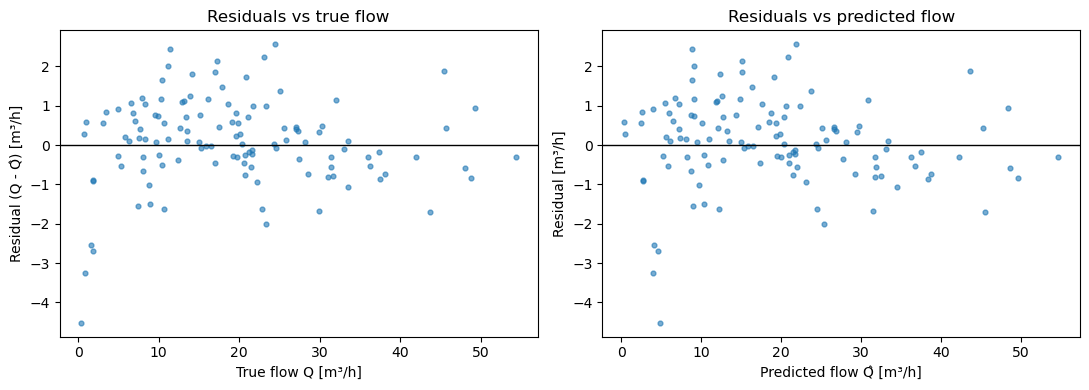

In [9]:
residuals = y_test - y_1_pred

# residuals vs true flow 
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(y_test, residuals, s=12, alpha=0.6)
axes[0].axhline(0, color="k", lw=1)
axes[0].set_xlabel("True flow Q [m³/h]")
axes[0].set_ylabel("Residual (Q - Q̂) [m³/h]")
axes[0].set_title("Residuals vs true flow")

# residuals vs predicted flow (standard diagnostic) 
axes[1].scatter(y_1_pred, residuals, s=12, alpha=0.6)
axes[1].axhline(0, color="k", lw=1)
axes[1].set_xlabel("Predicted flow Q̂ [m³/h]")
axes[1].set_ylabel("Residual [m³/h]")
axes[1].set_title("Residuals vs predicted flow")

plt.tight_layout()
plt.show()



The plots show the large errors happen at low flows and narrows a bit toward high flows suggesting heteroscedasticity. The model mostly ooverpredicts.